# Varredura v2 — dois mapas de features + diagnostico corrigido

Duas coisas de uma vez:

**(1) Diagnostico corrigido.** O teste da v1 estava mal desenhado. Ele correlacionava residuo
com AUC via Spearman, mas as duas grandezas nao tem essa geometria: o residuo **cai
monotonicamente** com `c`, enquanto o AUC e' **unimodal** (pico em c ~ 0.07). Correlacao
monotona nao mede monotona-contra-unimodal, e por isso saiu rho = -0.244.

Pior: o residuo de Frobenius e' **degenerado no limite c -> 0**. Ali a Gram vira quase toda de
uns e *qualquer* kernel a aproxima — dai o minimo de residuo em c=0.01 justamente onde o AUC
e' ruim. O residuo so mede classicalidade fora dessa regiao. A secao 5 filtra os pontos
degenerados por `gram_off_sd` e separa o ramo descendente antes de testar.

**(2) Mapa sem emaranhamento.** A mesma grade rodada com `entangle=False`. Se as duas
superficies coincidirem, a afirmacao do artigo sobe de "esse mapa ZZ nao ajuda" para
"a estrutura de emaranhamento e' irrelevante nesse regime" — que e' bem mais forte e bem mais
dificil de refutar.

Isso e' uma alegacao de **equivalencia**, nao de diferenca. Teste de significancia nao serve:
nao rejeitar H0 nao prova igualdade. A secao 6 usa TOST com margem pre-fixada em 0.01 de AUC.

In [2]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 105.0 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1


In [3]:
# !pip install pennylane -q
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
import pennylane as qml
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
from scipy.optimize import minimize_scalar
from scipy.stats import spearmanr, t as tdist
import warnings; warnings.filterwarnings("ignore")

In [4]:
PKL_PATH = "features_v5.pkl"
META = ["speaker_id", "session_id", "label", "diagnosis", "vowel", "pitch", "wav"]

feat = pd.read_pickle(PKL_PATH)
FEATS = [col for col in feat.columns if col not in META]
X_all = feat[FEATS].values.astype(float)
y_all = feat["label"].values.astype(int)
groups_all = feat["speaker_id"].values
assert not set(FEATS) & set(META), 'metadado vazando como feature'
print(f"{X_all.shape[0]} gravacoes | {len(FEATS)} features | {pd.unique(groups_all).size} falantes")

15766 gravacoes | 79 features | 1315 falantes


In [5]:
def _state_fn(n_qubits, reps, entangle):
    dev = qml.device("default.qubit", wires=n_qubits)
    @qml.qnode(dev)
    def circuit(x):
        for _ in range(reps):
            for i in range(n_qubits):
                qml.Hadamard(wires=i)
                qml.RZ(2.0 * x[..., i], wires=i)
            if entangle:
                for i in range(n_qubits - 1):
                    qml.CNOT(wires=[i, i + 1])
                    qml.RZ(2.0 * (np.pi - x[..., i]) * (np.pi - x[..., i + 1]), wires=i + 1)
                    qml.CNOT(wires=[i, i + 1])
        return qml.state()
    return circuit

def states(X, n_qubits, reps=2, entangle=True, batch=512):
    f = _state_fn(n_qubits, reps, entangle)
    return np.vstack([np.asarray(f(X[s:s + batch])) for s in range(0, len(X), batch)])

def gram(A, B):
    return np.abs(A @ B.conj().T) ** 2

def fit_surrogate(K_q, Xa):
    D2 = ((Xa[:, None, :] - Xa[None, :, :]) ** 2).sum(-1)
    loss = lambda lg: np.linalg.norm(K_q - np.exp(-np.exp(lg) * D2))
    r = minimize_scalar(loss, bounds=(-8, 6), method="bounded")
    return float(np.exp(r.x)), float(r.fun) / np.sqrt(K_q.size)

def align(K, y):
    Y = np.outer(2 * y - 1, 2 * y - 1)
    return float((K * Y).sum() / (np.linalg.norm(K) * np.linalg.norm(Y)))

def off_diag_sd(K):
    iu = np.triu_indices_from(K, k=1)
    return float(K[iu].std())

def subsample(ytr, gtr, n_per_class, rng):
    idx = []
    for cls in (0, 1):
        spk = rng.permutation(np.unique(gtr[ytr == cls]))
        take = []
        for s in spk:
            take += list(np.where((gtr == s) & (ytr == cls))[0])
            if len(take) >= n_per_class:
                break
        idx += take[:n_per_class]
    return np.array(idx)

## 3. Grade

Mesma grade da v1, agora rodada para os **dois** mapas. Sementes identicas as da v1
(`random_state=7`, `default_rng(1000*fold + rep)`), entao a metade `zz` deve reproduzir os
numeros que voce ja tem — se nao reproduzir, ha algo errado e vale parar antes de seguir.

In [6]:
QUBITS = [4, 6, 8, 10]
SCALES = np.round(np.geomspace(0.01, 2.0, 12), 4)
MAPAS = [("zz", True), ("prod", False)]
N_PER_CLASS = 200
N_FOLDS, N_REPS = 4, 3
C_SVM = 1.0
REPS_CIRCUITO = 2
MARGEM_EQUIV = 0.01          # margem de equivalencia em AUC, fixada ANTES de rodar

n_pontos = len(QUBITS) * len(SCALES) * len(MAPAS) * N_FOLDS * N_REPS
print(f"{n_pontos} avaliacoes de kernel — o dobro da v1 (dois mapas)")
print(f"estimativa: {n_pontos * 2.7 / 60:.0f}-{n_pontos * 4 / 60:.0f} min em CPU")
print("Nada e' reduzido automaticamente: ajuste QUBITS/SCALES/N_REPS se quiser.")

1152 avaliacoes de kernel — o dobro da v1 (dois mapas)
estimativa: 52-77 min em CPU
Nada e' reduzido automaticamente: ajuste QUBITS/SCALES/N_REPS se quiser.


In [7]:
rows = []
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=7)
t0 = time.time()

for fold, (tr, te) in enumerate(sgkf.split(X_all, y_all, groups_all)):
    for rep in range(N_REPS):
        rng = np.random.default_rng(1000 * fold + rep)
        sub = subsample(y_all[tr], groups_all[tr], N_PER_CLASS, rng)
        ytr, yte = y_all[tr][sub], y_all[te]
        imp = SimpleImputer(strategy="median").fit(X_all[tr][sub])
        Xtr_i, Xte_i = imp.transform(X_all[tr][sub]), imp.transform(X_all[te])

        for q in QUBITS:
            sel = SelectKBest(f_classif, k=q).fit(Xtr_i, ytr)
            sc = MinMaxScaler((0, np.pi)).fit(sel.transform(Xtr_i))
            A = sc.transform(sel.transform(Xtr_i))
            B = np.clip(sc.transform(sel.transform(Xte_i)), 0, np.pi)

            for cval in SCALES:
                Ac, Bc = A * cval, B * cval
                for nome, ent in MAPAS:
                    S1 = states(Ac, q, REPS_CIRCUITO, ent)
                    S2 = states(Bc, q, REPS_CIRCUITO, ent)
                    K1 = gram(S1, S1)
                    m = SVC(kernel="precomputed", C=C_SVM).fit(K1, ytr)
                    auc_q = roc_auc_score(yte, m.decision_function(gram(S2, S1)))
                    g_s, resid = fit_surrogate(K1, Ac)
                    ms = SVC(kernel="rbf", gamma=g_s, C=C_SVM).fit(Ac, ytr)
                    rows.append(dict(mapa=nome, fold=fold, rep=rep, n_qubits=q, c=cval,
                                     auc_q=auc_q,
                                     auc_surr=roc_auc_score(yte, ms.decision_function(Bc)),
                                     resid=resid, align=align(K1, ytr),
                                     gram_off_sd=off_diag_sd(K1), gamma_surr=g_s))
    print(f"fold {fold} ok — {time.time() - t0:.0f}s")

df = pd.DataFrame(rows)
agg = df.groupby(["mapa", "n_qubits", "c"]).mean(numeric_only=True).reset_index()
zz = agg[agg.mapa == "zz"]
print(zz.pivot(index="c", columns="n_qubits", values="auc_q").round(4).to_string())

fold 0 ok — 374s
fold 1 ok — 680s
fold 2 ok — 1010s
fold 3 ok — 1316s
n_qubits      4       6       8       10
c                                       
0.0100    0.6227  0.6275  0.6302  0.6365
0.0162    0.6244  0.6281  0.6316  0.6377
0.0262    0.6264  0.6297  0.6343  0.6405
0.0424    0.6278  0.6336  0.6393  0.6447
0.0687    0.6277  0.6367  0.6419  0.6468
0.1112    0.6287  0.6341  0.6363  0.6407
0.1799    0.6223  0.6266  0.6304  0.6336
0.2913    0.6166  0.6167  0.6208  0.6235
0.4715    0.6056  0.6107  0.6130  0.6164
0.7632    0.5958  0.6003  0.5991  0.5998
1.2355    0.5875  0.5874  0.5900  0.5884
2.0000    0.5630  0.5684  0.5701  0.5701


## 4. As duas superficies

Cada painel e' um numero de qubits. Linha cheia = ZZ (com emaranhamento), tracejada = produto
(sem). Se as curvas se sobrepuserem em toda a faixa de bandwidth, o emaranhamento nao esta
fazendo trabalho nenhum.

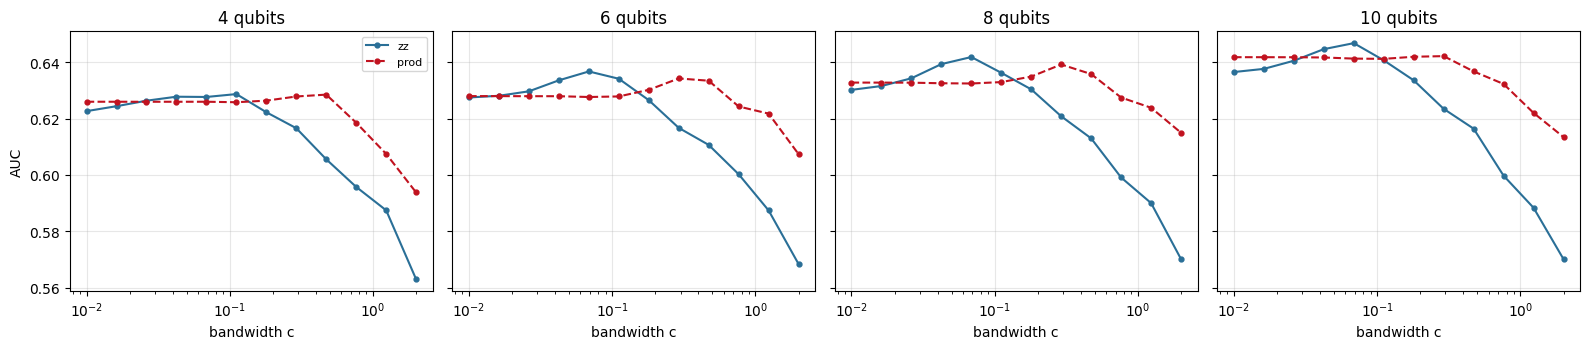

In [8]:
fig, ax = plt.subplots(1, len(QUBITS), figsize=(4 * len(QUBITS), 3.6), sharey=True)
for k, q in enumerate(QUBITS):
    a = ax[k] if len(QUBITS) > 1 else ax
    for nome, cor, ls in (("zz", "#2a6f97", "-"), ("prod", "#c1121f", "--")):
        g = agg[(agg.mapa == nome) & (agg.n_qubits == q)].sort_values("c")
        a.semilogx(g.c, g.auc_q, ls, color=cor, marker="o", ms=3.5, label=nome)
    a.set(xlabel="bandwidth c", title=f"{q} qubits"); a.grid(alpha=.3)
    if k == 0:
        a.set_ylabel("AUC"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Diagnostico corrigido do mecanismo

Tres testes, nesta ordem de importancia:

1. **`auc_q` vs `auc_surr`** — o teste primario. Se andam juntos, sao o mesmo modelo.
2. **`resid` vs `auc_q` fora da regiao degenerada** — o teste que a v1 fez errado.
3. **concentracao no ramo descendente** — explica a queda para `c` grande.

In [9]:
zz = agg[agg.mapa == "zz"]

piso = zz.gram_off_sd.max() * 0.05
nd = zz[zz.gram_off_sd > piso]
print(f"pontos nao degenerados: {len(nd)}/{len(zz)} (gram_off_sd > {piso:.5f})")

r1, p1 = spearmanr(zz.auc_q, zz.auc_surr)
d = (zz.auc_q - zz.auc_surr).abs()
print()
print(f"[1] Spearman(auc_q, auc_surr) = {r1:+.3f} (p={p1:.2g}) | "
      f"|dif| mediana={d.median():.4f} max={d.max():.4f}")

r2, p2 = spearmanr(nd.resid, nd.auc_q)
print(f"[2] Spearman(resid, auc_q) fora da degenerescencia = {r2:+.3f} (p={p2:.2g})")

desc = pd.concat([g[g.c >= g.loc[g.auc_q.idxmax(), "c"]]
                  for _, g in zz.groupby("n_qubits")])
r3, p3 = spearmanr(desc.gram_off_sd, desc.auc_q)
print(f"[3] Spearman(gram_off_sd, auc_q) no ramo descendente = {r3:+.3f} (p={p3:.2g})")
print()
if r1 > 0.9 and d.max() < 0.05:
    print("MECANISMO: o kernel quantico acompanha uma gaussiana classica em toda a grade.")
if r2 < -0.4 and p2 < 0.05:
    print("MECANISMO: fora da degenerescencia, melhor desempenho onde a aproximacao "
          "classica e' melhor — a hipotese original se sustenta.")
elif r2 > 0.4 and p2 < 0.05:
    print("ATENCAO: melhor desempenho onde a aproximacao classica FALHA. Isso contradiz "
          "a auditoria e precisa ser investigado antes de escrever.")

pontos nao degenerados: 47/48 (gram_off_sd > 0.01598)

[1] Spearman(auc_q, auc_surr) = +0.990 (p=1.8e-40) | |dif| mediana=0.0020 max=0.0157
[2] Spearman(resid, auc_q) fora da degenerescencia = -0.254 (p=0.085)
[3] Spearman(gram_off_sd, auc_q) no ramo descendente = +0.732 (p=2.8e-06)

MECANISMO: o kernel quantico acompanha uma gaussiana classica em toda a grade.


## 6. Equivalencia dos dois mapas (TOST)

"Nao rejeitei H0" nao prova igualdade. Para afirmar que o emaranhamento e' irrelevante e'
preciso um teste de **equivalencia**: mostrar que o IC da diferenca cabe inteiro dentro de
+/- `MARGEM_EQUIV`.

A unidade de analise e' o **fold**, nao a linha da grade: as repeticoes reamostram dentro dos
mesmos folds e as 48 celulas da grade compartilham os mesmos folds. Tratar tudo como
independente seria a mesma pseudorreplicacao que ja apareceu nos subgrupos.

In [10]:
piv = df.pivot_table(index=["n_qubits", "c", "fold"], columns="mapa",
                     values="auc_q").reset_index()
piv["delta"] = piv["zz"] - piv["prod"]

print(f"margem de equivalencia: +/- {MARGEM_EQUIV} de AUC (fixada antes de rodar)")
print()
linhas = []
for q, g in piv.groupby("n_qubits"):
    porfold = g.groupby("fold").delta.mean()          # unidade = fold
    n = len(porfold); mu = porfold.mean()
    se = porfold.std(ddof=1) / np.sqrt(n)
    tc = tdist.ppf(0.975, n - 1)
    lo, hi = mu - tc * se, mu + tc * se
    if (lo > -MARGEM_EQUIV) and (hi < MARGEM_EQUIV):
        vered = "equivalente"
    elif (hi < -MARGEM_EQUIV) or (lo > MARGEM_EQUIV):
        vered = "diferenca real"     # IC inteiro fora da margem
    else:
        vered = "inconclusivo"       # IC atravessa a margem: falta poder
    linhas.append(dict(n_qubits=q, n_folds=n, delta_medio=mu, ic95_lo=lo, ic95_hi=hi,
                       veredito=vered))
res = pd.DataFrame(linhas)
print(res.round(4).to_string(index=False))

dentro = (piv.groupby(["n_qubits", "c"]).delta.mean().abs() < MARGEM_EQUIV).mean()
r_map, p_map = spearmanr(agg[agg.mapa == "zz"].auc_q.values,
                         agg[agg.mapa == "prod"].auc_q.values)
print()
print(f"celulas da grade com |delta| < {MARGEM_EQUIV}: {dentro:.0%}")
print(f"Spearman(auc_zz, auc_prod) sobre a grade = {r_map:+.3f} (p={p_map:.2g})")
print()
eq = (res.veredito == "equivalente"); dif = (res.veredito == "diferenca real")
if eq.all():
    print("EQUIVALENCIA ESTABELECIDA em todos os numeros de qubits: a estrutura de "
          "emaranhamento e' irrelevante nesse regime. Essa e' a afirmacao forte do artigo.")
elif dif.any():
    lado = "ABAIXO" if res[dif].delta_medio.mean() < 0 else "ACIMA"
    print(f"DIFERENCA REAL em {list(res[dif].n_qubits)}: o mapa ZZ fica {lado} do produto "
          "por mais que a margem. Nao e' equivalencia — e' o emaranhamento ATRAPALHANDO. "
          "Afirmacao ainda mais forte que a planejada, mas exige reescrever a hipotese: "
          "o custo do emaranhamento nao se paga nem em desempenho.")
elif eq.any():
    print(f"Equivalencia so em {list(res[eq].n_qubits)}. Reporte por numero de qubits.")
else:
    print("INCONCLUSIVO: o IC atravessa a margem. Falta poder — aumentar N_FOLDS "
          "adiciona informacao independente; N_REPS nao.")

margem de equivalencia: +/- 0.01 de AUC (fixada antes de rodar)

 n_qubits  n_folds  delta_medio  ic95_lo  ic95_hi     veredito
        4        4      -0.0092  -0.0189   0.0005 inconclusivo
        6        4      -0.0099  -0.0191  -0.0008 inconclusivo
        8        4      -0.0113  -0.0180  -0.0046 inconclusivo
       10        4      -0.0133  -0.0244  -0.0022 inconclusivo

celulas da grade com |delta| < 0.01: 58%
Spearman(auc_zz, auc_prod) sobre a grade = +0.659 (p=3.5e-07)

INCONCLUSIVO: o IC atravessa a margem. Falta poder — aumentar N_FOLDS adiciona informacao independente; N_REPS nao.


## 7. O que isso da ao artigo

- Secao 4: figura de duas superficies — sustenta a afirmacao sobre emaranhamento sem uma linha de texto.
- Secao 5: o mecanismo, agora medido com a geometria certa.
- Secao 6: equivalencia com margem pre-registrada, que e' o padrao que um referee metodologico espera.

E o argumento que fecha a discussao: **a auditoria nao precisa de hardware real**. Voce nao esta
reivindicando vantagem quantica — esta mostrando que ela nao aparece sob controle adequado, e a
simulacao de statevector e' exata. Isso neutraliza a objecao que derrubaria um artigo de
proposta de arquitetura.